In [58]:
import pandas as pd
import numpy as np

In [59]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/MNIST.csv')

In [60]:
df.shape

(42000, 785)

In [61]:
df.sample(5)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
37023,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
34030,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
32982,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41324,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
27234,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


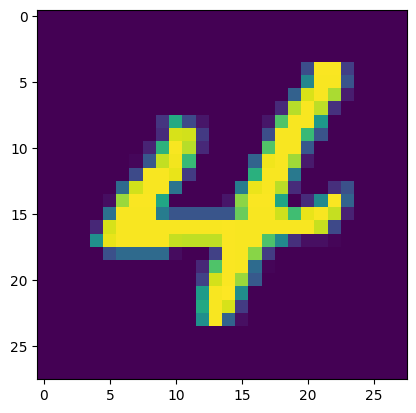

In [62]:
import matplotlib.pyplot as plt
plt.imshow(df.iloc[4397,1:].values.reshape(28,28))

In [63]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [66]:
knn = KNeighborsClassifier()

In [67]:
knn.fit(X_train,y_train)


KNeighborsClassifier()

In [68]:
import time

In [69]:
start = time.time()
y_pred = knn.predict(X_test)
print(time.time() - start)

8.00515103340149


In [70]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9648809523809524

# With PCA

In [71]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [72]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [73]:
from sklearn.decomposition import PCA
pca = PCA(n_components=200)


In [74]:
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [75]:
X_train_trf.shape

(33600, 200)

In [76]:
knn = KNeighborsClassifier()

In [77]:
knn.fit(X_train_trf,y_train)
y_pred_trf = knn.predict(X_test_trf)

In [78]:
accuracy_score(y_test, y_pred_trf)

0.9507142857142857

In [79]:
# for i in range(1,784):
#     pca = PCA(n_components=i)
#     X_train_trf = pca.fit_transform(X_train)
#     X_test_trf = pca.transform(X_test)
#     knn = KNeighborsClassifier()
#     knn.fit(X_train_trf,y_train)
#     y_pred_trf = knn.predict(X_test_trf)
#     print(f"Accuracy With {i} number of columns ->",accuracy_score(y_test, y_pred_trf))

In [82]:
pca = PCA(n_components=2)

X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)



In [84]:
import plotly.express as px
y_train_trf = y_train.astype(str)
fig = px.scatter(x=X_train_trf[:,0],
                 y=X_train_trf[:,1],
                 color=y_train_trf,
                 color_discrete_sequence=px.colors.qualitative.G10
                 )

fig.show()

In [85]:
pca = PCA(n_components=3)

X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [94]:
y_train_trf = y_train.astype(str)

fig = px.scatter_3d(
    X_test_trf,
    x=X_train_trf[:, 0],
    y=X_train_trf[:, 1],
    z=X_train_trf[:, 2],
    color=y_train_trf
)

fig.update_layout(
    margin=dict(l=20, r=20, t=20, b=20),
    width=1200,  # 13 inches × ~100 dpi
    height=700
)

fig.show()

In [95]:
pca.explained_variance_

array([40.67111198, 29.17023401, 26.74459621])

In [97]:
pca.components_.shape

(3, 784)

In [98]:
pca = PCA(n_components=None)

X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [99]:
pca.explained_variance_.shape

(784,)

In [100]:
pca.components_.shape

(784, 784)

In [101]:
pca.explained_variance_ratio_

array([5.78519225e-02, 4.14926968e-02, 3.80423901e-02, 2.96626277e-02,
       2.58156168e-02, 2.25498018e-02, 1.97306802e-02, 1.77527998e-02,
       1.56865066e-02, 1.43606328e-02, 1.37025484e-02, 1.22725500e-02,
       1.14691200e-02, 1.12302739e-02, 1.05852885e-02, 1.01993106e-02,
       9.57676152e-03, 9.42708817e-03, 9.12489429e-03, 8.90170190e-03,
       8.39940495e-03, 8.20063196e-03, 7.85303229e-03, 7.56739707e-03,
       7.37261022e-03, 7.01884653e-03, 6.97919728e-03, 6.71104483e-03,
       6.39845030e-03, 6.30337291e-03, 6.15350848e-03, 6.02388659e-03,
       5.83673972e-03, 5.78547759e-03, 5.72333148e-03, 5.46399774e-03,
       5.43207369e-03, 5.28172755e-03, 5.13381744e-03, 4.94015474e-03,
       4.87671103e-03, 4.81978768e-03, 4.68204430e-03, 4.59342487e-03,
       4.57660834e-03, 4.49219022e-03, 4.44682221e-03, 4.41540749e-03,
       4.35111936e-03, 4.32032928e-03, 4.21808870e-03, 4.18243127e-03,
       4.07994349e-03, 4.02004913e-03, 3.98335855e-03, 3.94598812e-03,
      

In [102]:
np.cumsum(pca.explained_variance_ratio_)

array([0.05785192, 0.09934462, 0.13738701, 0.16704964, 0.19286525,
       0.21541506, 0.23514574, 0.25289854, 0.26858504, 0.28294568,
       0.29664822, 0.30892077, 0.32038989, 0.33162017, 0.34220546,
       0.35240477, 0.36198153, 0.37140862, 0.38053351, 0.38943521,
       0.39783462, 0.40603525, 0.41388828, 0.42145568, 0.42882829,
       0.43584714, 0.44282633, 0.44953738, 0.45593583, 0.4622392 ,
       0.46839271, 0.4744166 , 0.48025334, 0.48603881, 0.49176214,
       0.49722614, 0.50265822, 0.50793994, 0.51307376, 0.51801392,
       0.52289063, 0.52771041, 0.53239246, 0.53698588, 0.54156249,
       0.54605468, 0.5505015 , 0.55491691, 0.55926803, 0.56358836,
       0.56780645, 0.57198888, 0.57606882, 0.58008887, 0.58407223,
       0.58801822, 0.59188694, 0.59571889, 0.59948441, 0.60322635,
       0.60687487, 0.6104829 , 0.61402176, 0.61750117, 0.62094441,
       0.62432378, 0.62767368, 0.63099377, 0.63426257, 0.63746765,
       0.64065542, 0.64376931, 0.64686564, 0.64992395, 0.65296

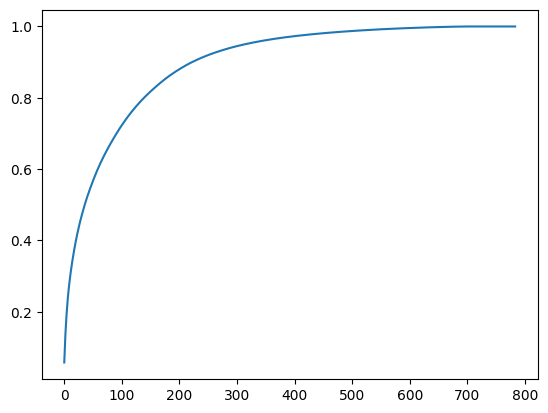

In [103]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))